# 05 — Huấn luyện mô hình GNN (Model Training)

## 1. Mục tiêu
Notebook này giải thích và trực quan hóa **Bước 5** trong quy trình XAI-Football:
- Kiến trúc GNN: GCN (đề xuất đơn giản), MPNN (đề xuất chính), GATv2 (baseline attention), GraphSAGE (baseline sampling).
- Cấu hình siêu tham số chung: Cố định seed, Optimizer AdamW, LR scheduler ReduceLROnPlateau, Early Stopping (monitor: validation AUC-PR).
- Đọc và phân tích lịch sử huấn luyện (`training_history.csv`) của các mô hình đã huấn luyện chính thức.
- Vẽ đường cong Train Loss và Validation Loss theo epoch.
- Vẽ đường cong Validation AUC-PR theo epoch và xác định Best Epoch.
- Notebook chỉ đọc lịch sử thực nghiệm đã có (5 seed / mô hình), không tự huấn luyện lại.

## 2. Vị trí của bước trong pipeline
Đây là **Bước 5 — Huấn luyện mô hình GNN (`scripts/06_train.py`, `src/xai_football/training/`)**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

# Gốc repo: chạy được cả khi kernel đứng ở notebooks/ (mặc định của Jupyter/nbconvert)
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())
figures_dir = REPO_ROOT / "results" / "figures" / "official"
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 150

## 3. Input và nguồn dữ liệu
- Cấu hình huấn luyện: `configs/train.yaml`, `configs/model/*.yaml`.
- Lịch sử huấn luyện của từng seed: `experiments/official/<model>/<seed>/training_history.csv`.
- Tổng hợp multi-seed: `experiments/official/<model>/aggregate_summary.json`.

## 4. Config/script/module sử dụng
- Scripts: `scripts/06_train.py`, `scripts/06_train_baselines.py`.
- Module: `src/xai_football/training/trainer.py`, `losses.py`, `modeling/gnn/`.

## 5. Các bước xử lý & Đọc cấu hình thực tế

In [2]:
with open(REPO_ROOT / "configs" / "train.yaml", encoding="utf-8") as f:
    train_cfg = yaml.safe_load(f)

print("=== CẤU HÌNH HUẤN LUYỆN CHUNG (configs/train.yaml) ===")
print(f"Seed mặc định:     {train_cfg.get('seed')}")
print(f"Seeds cấu hình:    {train_cfg.get('seeds')}")
print(f"Epochs tối đa:     {train_cfg.get('epochs')}")
print(f"Batch size:        {train_cfg.get('batch_size')}")
print(f"Optimizer:         {train_cfg.get('optimizer')}")
print(f"Scheduler:         {train_cfg.get('scheduler')}")
print(f"Early stopping:    {train_cfg.get('early_stopping')}")

=== CẤU HÌNH HUẤN LUYỆN CHUNG (configs/train.yaml) ===
Seed mặc định:     42
Seeds cấu hình:    [42, 123, 456, 789, 1024]
Epochs tối đa:     200
Batch size:        64
Optimizer:         {'name': 'adamw', 'lr': 0.001, 'weight_decay': 0.0001}
Scheduler:         {'name': 'reduce_on_plateau', 'monitor': 'val_auc_pr', 'patience': 10, 'factor': 0.5}
Early stopping:    {'monitor': 'val_auc_pr', 'mode': 'max', 'patience': 20}


In [3]:
import json

# Đọc lịch sử huấn luyện của MỌI seed cho từng mô hình GNN
models = ["mpnn", "gcn", "gatv2", "graphsage"]
histories = {}   # (model, seed) -> DataFrame
aggregates = {}  # model -> aggregate_summary.json

for m in models:
    model_dir = REPO_ROOT / "experiments" / "official" / m
    agg_path = model_dir / "aggregate_summary.json"
    if not agg_path.exists():
        raise FileNotFoundError(
            f"Thiếu {agg_path}. Hãy chạy: python scripts/06_train.py --model-config configs/model/{m}.yaml"
        )
    aggregates[m] = json.loads(agg_path.read_text(encoding="utf-8"))
    for seed in aggregates[m]["successful_seeds"]:
        histories[(m, seed)] = pd.read_csv(model_dir / str(seed) / "training_history.csv")

df_runs = pd.DataFrame([
    {
        "model": m.upper(),
        "seeds": len(a["successful_seeds"]),
        "complete": a["is_complete_official"],
        "best_seed_by_val": a.get("best_seed_by_val_auc_pr"),
        "val_auc_pr_mean": a["val_metrics_summary"]["mean"]["auc_pr"],
        "val_auc_pr_std": a["val_metrics_summary"]["std"]["auc_pr"],
    }
    for m, a in aggregates.items()
])
display(df_runs)

,model,seeds,complete,best_seed_by_val,val_auc_pr_mean,val_auc_pr_std
0,MPNN,5,True,789,0.5847,0.0015
1,GCN,5,True,789,0.4168,0.0027
2,GATV2,5,True,1024,0.4373,0.0058
3,GRAPHSAGE,5,True,1024,0.4903,0.0037


## 6. Kết quả và cách diễn giải
### 6.1. Đường cong Validation AUC-PR theo Epoch

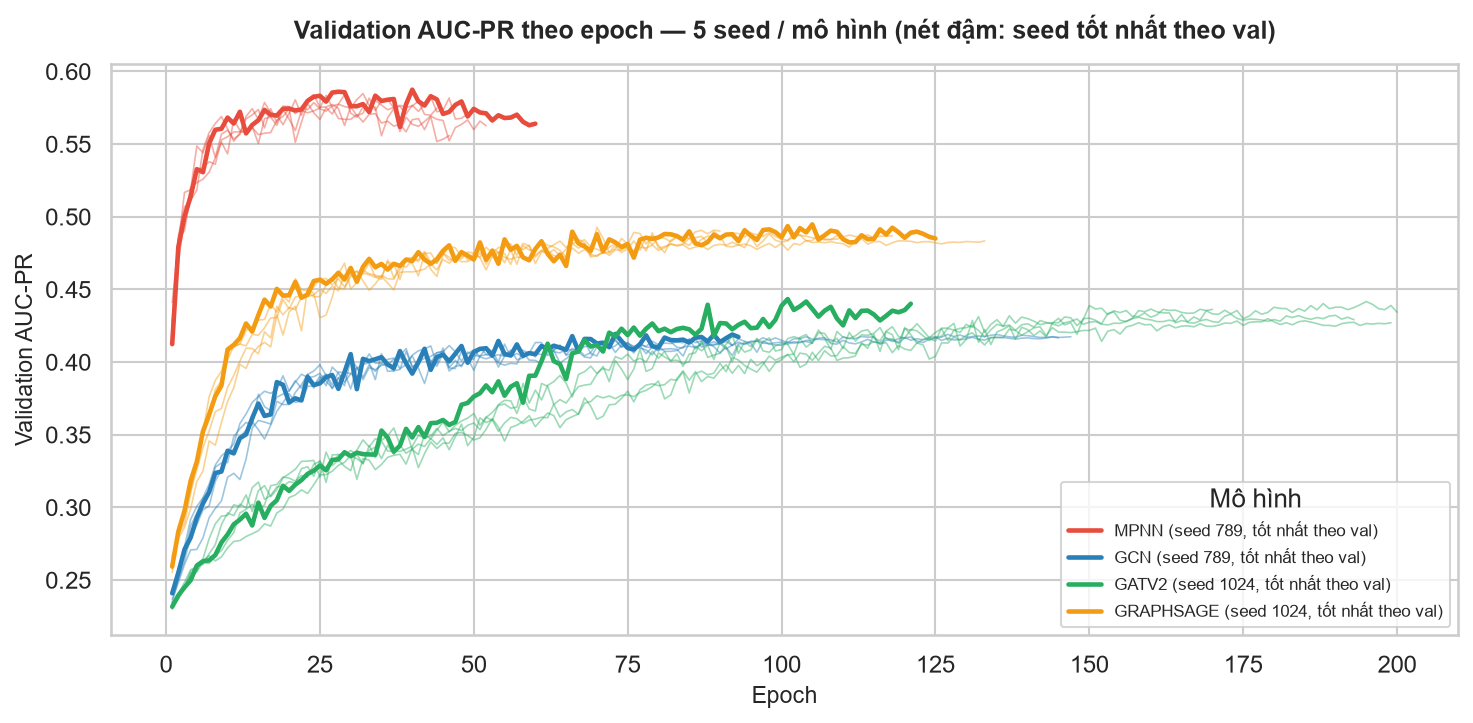

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {"mpnn": "#e74c3c", "gcn": "#2980b9", "gatv2": "#27ae60", "graphsage": "#f39c12"}

for (m, seed), df_h in histories.items():
    is_best = seed == aggregates[m].get("best_seed_by_val_auc_pr")
    ax.plot(df_h["epoch"], df_h["val_auc_pr"], color=colors[m], linewidth=2.2 if is_best else 0.8,
            alpha=1.0 if is_best else 0.45, label=f"{m.upper()} (seed {seed}, tốt nhất theo val)" if is_best else None)

ax.set_title("Validation AUC-PR theo epoch — 5 seed / mô hình (nét đậm: seed tốt nhất theo val)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel("Validation AUC-PR", fontsize=11)
ax.legend(title="Mô hình", loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(figures_dir / "05_val_auc_pr_curves.png", dpi=300)
plt.savefig(figures_dir / "05_val_auc_pr_curves.svg")
plt.show()

### 6.2. Đường cong Train Loss và Validation Loss của mô hình MPNN (đề xuất chính)

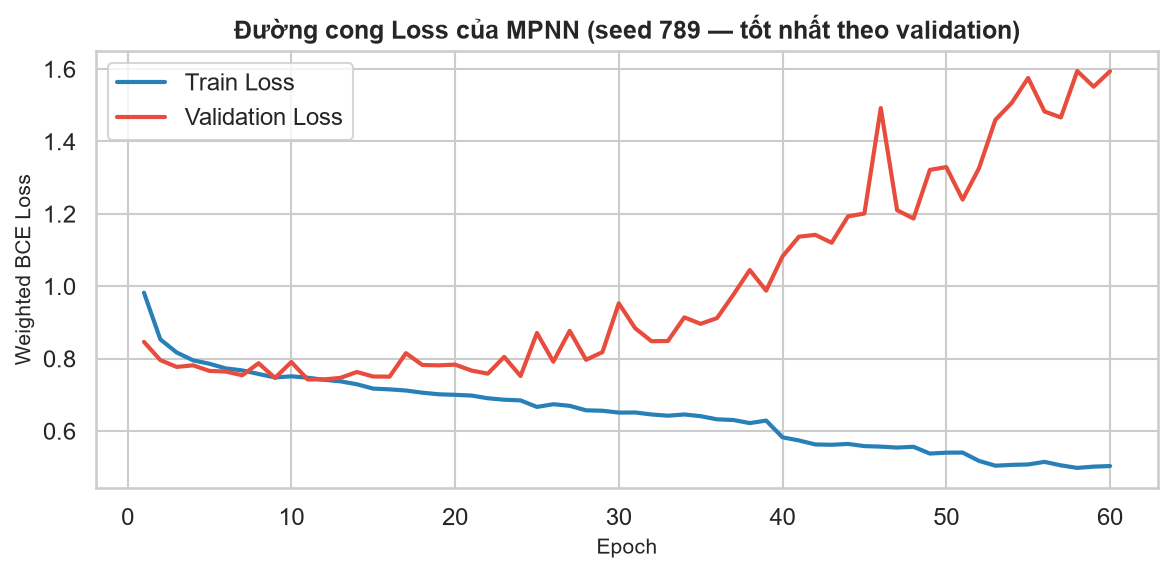

In [5]:
best_seed = aggregates["mpnn"]["best_seed_by_val_auc_pr"]
df_mpnn = histories[("mpnn", best_seed)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df_mpnn["epoch"], df_mpnn["train_loss"], label="Train Loss", color="#2980b9", linewidth=2)
ax.plot(df_mpnn["epoch"], df_mpnn["val_loss"], label="Validation Loss", color="#e74c3c", linewidth=2)
ax.set_title(f"Đường cong Loss của MPNN (seed {best_seed} — tốt nhất theo validation)", fontsize=12, fontweight="bold")
ax.set_xlabel("Epoch", fontsize=10)
ax.set_ylabel("Weighted BCE Loss", fontsize=10)
ax.legend()
plt.tight_layout()
plt.savefig(figures_dir / "05_training_loss_curves.png", dpi=300)
plt.savefig(figures_dir / "05_training_loss_curves.svg")
plt.show()

## 7. Kiểm tra chất lượng (Quality Checks)

In [6]:
rows = []
for (m, seed), df_h in histories.items():
    # Best epoch / Val AUC-PR lấy từ run_manifest.json — đúng epoch mà trainer đã lưu checkpoint
    # (trainer chỉ nhận cải thiện > 1e-5, nên không dùng idxmax trên lịch sử).
    manifest = json.loads(
        (REPO_ROOT / "experiments" / "official" / m / str(seed) / "run_manifest.json").read_text(encoding="utf-8")
    )
    best_epoch = int(manifest["best_epoch"])
    rows.append({
        "Model": m.upper(),
        "Seed": seed,
        "No NaN/Inf": "PASS" if not df_h.isna().any().any() else "FAIL",
        "Epochs": len(df_h),
        "Best epoch": best_epoch,
        "Val PR tại best epoch": round(float(df_h.loc[df_h["epoch"] == best_epoch, "val_auc_pr"].iloc[0]), 4),
        "Lịch sử khớp manifest": "PASS" if len(df_h) == manifest["epochs_run"] else "FAIL",
    })
df_qc = pd.DataFrame(rows)
print("=== KIỂM TRA CHẤT LƯỢNG LỊCH SỬ HUẤN LUYỆN (mọi seed) ===")
display(df_qc)
assert (df_qc["No NaN/Inf"] == "PASS").all(), "Lịch sử huấn luyện chứa giá trị NaN/Inf!"
assert (df_qc["Lịch sử khớp manifest"] == "PASS").all(), "training_history.csv không khớp run_manifest.json!"
assert df_runs["complete"].all() and (df_runs["seeds"] == 5).all(), "Có mô hình chưa chạy đủ 5 seed!"

=== KIỂM TRA CHẤT LƯỢNG LỊCH SỬ HUẤN LUYỆN (mọi seed) ===


,Model,Seed,No NaN/Inf,Epochs,Best epoch,Val PR tại best epoch,Lịch sử khớp manifest
0,MPNN,42,PASS,52,32,0.5847,PASS
1,MPNN,123,PASS,49,29,0.5841,PASS
2,MPNN,456,PASS,46,26,0.5835,PASS
3,MPNN,789,PASS,60,40,0.5874,PASS
4,MPNN,1024,PASS,44,24,0.5840,PASS
5,GCN,42,PASS,105,85,0.4157,PASS
6,GCN,123,PASS,92,72,0.4128,PASS
7,GCN,456,PASS,147,127,0.4190,PASS
8,GCN,789,PASS,93,73,0.4193,PASS
9,GCN,1024,PASS,145,125,0.4172,PASS


## 8. Output được lưu ở đâu
- Thư mục thí nghiệm: `experiments/official/<model>/<seed>/` (từng seed) và
  `experiments/official/<model>/` (aggregate_summary.json, *_all_seeds.csv, bản sao seed tốt nhất)
  - `training_history.csv`
  - `best_model.pt`
  - `validation_metrics.csv`
  - `test_metrics.csv`
  - `run_manifest.json`
- Trọng số chính thức: `models/official/<model>_best.pt`
- Biểu đồ:
  - `results/figures/official/05_val_auc_pr_curves.png` (và `.svg`)
  - `results/figures/official/05_training_loss_curves.png` (và `.svg`)

## 9. Cách tái chạy
Chạy thử smoke test nhanh (1 epoch, hoàn tất trong ~1 giây):
```bash
python scripts/06_train.py --model-config configs/model/mpnn.yaml --smoke-test
```
Chạy huấn luyện đầy đủ (nhiều seed):
```bash
python scripts/06_train.py --model-config configs/model/mpnn.yaml --seeds 42,123,456,789,1024
# lặp lại cho gcn.yaml, gatv2.yaml, graphsage.yaml; baseline:
python scripts/06_train_baselines.py --config configs/data.yaml
```

## 10. Giới hạn và giả định
- Để tiết kiệm tài nguyên tính toán, notebook mặc định đọc các file artifact đã lưu thay vì tự động kích hoạt huấn luyện lại từ đầu.